## 1. Setup and data loading

In [1]:
# Colab already has these; uncomment if running elsewhere
# !pip install -q statsmodels openpyxl

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.discrete.conditional_models import ConditionalLogit
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
SEED = 42

In [2]:
# Dataset: Diabetic CKD dataset (Mendeley Data, doi:10.17632/hjkzgbxgv5.2)
# A copy is hosted on Google Drive so the notebook runs without uploading anything.
DRIVE_FILE_ID = "1qdWJNVhQ4VeBhfoZiIn--2hgr-CkeKS_"
DATA_URL = f"https://drive.google.com/uc?export=download&id={DRIVE_FILE_ID}"
LOCAL_PATH = "DiabeticCKD_dataset.csv"   # used if the file is already next to the notebook

if os.path.exists(LOCAL_PATH):
    raw = pd.read_csv(LOCAL_PATH)
    print("Loaded local file:", LOCAL_PATH)
else:
    raw = pd.read_csv(DATA_URL)
    print("Loaded from Google Drive")

print(raw.shape)          # expected: (4000, number of columns)
raw.head(3)

Loaded from Google Drive
(4000, 26)


,Patient ID,"Gender (M-male, F-female)","Job (1-normal, 2-intermediate, 3-heavy)","Family Background of Diabetes (1-yes, 0-no)",Height (cm),Diabetic Year,Age,Average Age,Weight (kg),Average Weight (kg),BMI,"Follow suggested Diet (1-yes, 0-no)","Take Medicine for Diabetes (1-yes, 0-no)","Take Insulin (1-yes, 0-no)","Hypertension (1-yes, 0-no)","Heart Disease (1-yes, 0-no)","Sleep (1-sufficient, 0-insufficient)","Water Consumption (1-sufficient, 0-insufficient)","Smoke (1-yes, 0-no)","Zarda, Betel Leaf (1-yes, 0-no)","Walk Regularly (1-yes, 0-no)","Urination Properly (1-yes, 0-no)","Urinary Infection (1-yes, 0-no)","Pain killer (1-yes, 0-no)",Calorie Intake (per day),"CKD (1-yes, 0-no)"
0,1,F,1,0,158.5,1,48,53,49,49.5,19.7,1,0,1,0,0,0,1,0,0,0,1,0,1,1800,0
1,1,F,1,0,158.5,2,49,53,49,49.5,19.7,0,0,1,0,0,0,1,0,0,0,1,0,1,1800,0
2,1,F,1,0,158.5,3,50,53,49,49.5,19.7,1,0,1,0,0,0,1,0,0,0,1,0,1,1800,0


In [3]:
# Short column names (order as in the Mendeley file)
NAMES = ['id','sex','job','fam','height','dy','age','avg_age','wt','avg_wt','bmi','diet','med','ins',
         'htn','hd','sleep','water','smoke','zarda','walk','urin','uti','pain','cal','ckd']
assert raw.shape[1] == len(NAMES), "Unexpected number of columns"
df = raw.copy(); df.columns = NAMES
df['male'] = (df['sex'].str.upper() == 'M').astype(int)
df = df.sort_values(['id','dy']).reset_index(drop=True)

LABELS = {'ins':'Insulin use','med':'Diabetes medication','diet':'Diet adherence','htn':'Hypertension',
          'hd':'Heart disease','walk':'Walks regularly','uti':'Urinary infection','pain':'Regular painkiller use',
          'sleep':'Sufficient sleep','water':'Sufficient water','smoke':'Smoking','zarda':'Zarda / betel leaf',
          'urin':'Urinates properly','wt':'Weight','age':'Age (per 10 y)','male':'Male sex','bmi':'BMI (per kg/m²)',
          'cal':'Calorie intake (per 100 kcal/d)','job':'Job exertion','wt_sd':'Weight variability (per 1 kg SD)'}

## 2. Data structure checks

In [4]:
g = df.groupby('id')
pt = pd.DataFrame({'start': g.dy.min(), 'end': g.dy.max(), 'n_rec': g.size(), 'case': g.ckd.max()})
pt['onset'] = df[df.ckd == 1].groupby('id').dy.min()

consecutive = g.dy.apply(lambda s: (s.diff().dropna() == 1).all()).all()
monotone = g.ckd.apply(lambda s: (s.diff().dropna() >= 0).all()).all()
print(f"Patients: {len(pt)} | cases: {pt.case.sum()} | controls: {(pt.case==0).sum()}")
print(f"10 records per patient: {(pt.n_rec==10).all()} | consecutive years: {consecutive} | CKD never reverts: {monotone}")
print(f"CKD at first record: {(df.groupby('id').ckd.first()==1).sum()}")
cases = pt[pt.case == 1]
print(f"Cases with onset in last record: {(cases.onset==cases.end).sum()} | onset earlier (post-onset rows exist): {(cases.onset<cases.end).sum()}")
print(f"Years of pre-onset data per case: median {(cases.onset-cases.start).median():.0f}; >=5 years in {((cases.onset-cases.start)>=5).sum()} cases")

Patients: 400 | cases: 185 | controls: 215
10 records per patient: True | consecutive years: True | CKD never reverts: True
CKD at first record: 0
Cases with onset in last record: 127 | onset earlier (post-onset rows exist): 58
Years of pre-onset data per case: median 9; >=5 years in 164 cases


In [5]:
# Which variables genuinely vary within patients? (Supplementary table)
# Near-constant variables behave like a single report at interview; varying ones like annual record-book entries.
post = df.merge(pt[['onset']], left_on='id', right_index=True)
post = post[post.onset.notna() & (post.groupby('id').dy.transform('max') > post.onset)]
rows = []
for v in ['ins','med','diet','htn','wt','walk','uti','pain','hd','sleep','smoke','water','zarda','urin']:
    const = (g[v].nunique() == 1).mean() * 100
    pre_m = post[post.dy < post.onset].groupby('id')[v].mean()
    post_m = post[post.dy >= post.onset].groupby('id')[v].mean()
    rows.append([LABELS[v], round(const,1), round((pre_m != post_m).mean()*100, 1)])
const_tab = pd.DataFrame(rows, columns=['Variable','% patients identical in all 10 years',
                                        f'% changed after CKD onset ({post.id.nunique()} cases)'])
const_tab['Treated as'] = np.where(const_tab.iloc[:,1] < 95, 'time-varying (record book)', 'static (reported at interview)')
const_tab

,Variable,% patients identical in all 10 years,% changed after CKD onset (58 cases),Treated as
0,Insulin use,66.0,27.6,time-varying (record book)
1,Diabetes medication,77.2,12.1,time-varying (record book)
2,Diet adherence,73.2,10.3,time-varying (record book)
3,Hypertension,89.0,8.6,time-varying (record book)
4,Weight,0.5,96.6,time-varying (record book)
5,Walks regularly,98.8,0.0,static (reported at interview)
6,Urinary infection,96.2,0.0,static (reported at interview)
7,Regular painkiller use,96.8,5.2,static (reported at interview)
8,Heart disease,95.0,3.4,static (reported at interview)
9,Sufficient sleep,99.5,0.0,static (reported at interview)


### Supplementary Table S2: reproduction of figures reported in the data descriptor
Every figure reported in Anan et al. (2026) is recomputed from the released file. Patient-level binary characteristics are evaluated under three definitions (present in ≥50% of years, in any year, or in the last record), and age under five (last record, first record, mean of records, the file's "Average Age" column, and age at first CKD record for cases). A figure is classed as **reproduced** if any definition falls within tolerance: counts exact, percentages within 0.5 percentage points, means within 0.05 (age within 0.5 years) and correlations within 0.01.

In [6]:
def _P():
    gg = df.groupby('id')
    Q = pd.DataFrame({'case': gg.ckd.max(), 'sex': gg.sex.first(), 'job': gg.job.first(), 'bmi': gg.bmi.first(),
                      'age_last': gg.age.last(), 'age_first': gg.age.first(), 'age_mean': gg.age.mean(), 'avg_age': gg.avg_age.first()})
    Q['age_onset'] = df[df.ckd == 1].groupby('id').age.min()
    for v in ['htn','sleep','water','smoke','zarda','fam']:
        Q[v+'_half'] = (gg[v].mean() >= .5).astype(int); Q[v+'_any'] = gg[v].max(); Q[v+'_last'] = gg[v].last()
    return Q
Q = _P(); QC, QN = Q[Q.case == 1], Q[Q.case == 0]
AGE_DEFS = ['age_last','age_first','age_mean','avg_age']
pct = lambda s: s.mean() * 100
rows = []
def add(item, reported, candidates, tol, kind):
    # candidates: dict definition -> value; pick the closest
    best_def, best_val = min(candidates.items(), key=lambda kv: abs(kv[1] - reported))
    ok = abs(best_val - reported) <= tol
    rows.append([item, reported, round(best_val, 2), best_def, 'Yes' if ok else 'No'])

add('Patients, n', 400, {'file': len(Q)}, 0, 'n')
add('Patients with CKD, n', 185, {'file': len(QC)}, 0, 'n')
add('Patients with CKD, %', 46.25, {'file': pct(Q.case)}, .5, '%')
add('Patients without CKD, n', 215, {'file': len(QN)}, 0, 'n')
add('Women among patients with CKD, n', 113, {'file': (QC.sex == 'F').sum()}, 0, 'n')
add('Men among patients with CKD, n', 72, {'file': (QC.sex == 'M').sum()}, 0, 'n')
add('Mean age, patients with CKD, y', 54.17, {**{a: QC[a].mean() for a in AGE_DEFS}, 'age at first CKD record': QC.age_onset.mean()}, .5, 'mean')
add('Mean age, patients without CKD, y', 49.10, {a: QN[a].mean() for a in AGE_DEFS}, .5, 'mean')
add('Difference in mean age (CKD − no CKD), y', 54.17 - 49.10, {a: QC[a].mean() - QN[a].mean() for a in AGE_DEFS}, .5, 'mean')
add('Patients with CKD older than 45 y, %', 87.6, {a: pct(QC[a] > 45) for a in AGE_DEFS + ['age_onset']}, .5, '%')
add('Patients with CKD younger than 40 y, n', 8, {a: (QC[a] < 40).sum() for a in AGE_DEFS + ['age_onset']}, 0, 'n')
# Age range must come from a single definition: both limits have to match
_ranges = {'all records': (df.age.min(), df.age.max()), 'avg_age': (Q.avg_age.min(), Q.avg_age.max()),
           'age_first': (Q.age_first.min(), Q.age_first.max()), 'age_last': (Q.age_last.min(), Q.age_last.max())}
_ok = [k for k, (lo, hi) in _ranges.items() if lo == 21 and hi == 80]
_best = _ok[0] if _ok else min(_ranges, key=lambda k: abs(_ranges[k][0]-21) + abs(_ranges[k][1]-80))
rows.append(['Age range, y', '21–80', f"{_ranges[_best][0]}–{_ranges[_best][1]}", _best, 'Yes' if _ok else 'No'])
add('Patients with CKD in sedentary (normal) jobs, n', 140, {'job = normal': (QC.job == 1).sum()}, 0, 'n')
add('Patients with CKD in intermediate jobs, n', 31, {'job = intermediate': (QC.job == 2).sum()}, 0, 'n')
add('Patients with CKD in heavy jobs, n', 14, {'job = heavy': (QC.job == 3).sum()}, 0, 'n')
add('Mean BMI, patients with CKD, kg/m²', 24.81, {'file': QC.bmi.mean()}, .05, 'mean')
add('Mean BMI, patients without CKD, kg/m²', 24.03, {'file': QN.bmi.mean()}, .05, 'mean')
for item, rep, v, grp, inv in [('Hypertension, patients with CKD, %', 30.81, 'htn', QC, False),
                               ('Insufficient sleep, patients with CKD, %', 45.41, 'sleep', QC, True),
                               ('Insufficient sleep, patients without CKD, %', 35.35, 'sleep', QN, True),
                               ('Adequate water intake, patients with CKD, %', 88.11, 'water', QC, False),
                               ('Adequate water intake, patients without CKD, %', 92.56, 'water', QN, False),
                               ('Smoking, patients with CKD, %', 16.22, 'smoke', QC, False),
                               ('Smoking, patients without CKD, %', 10.70, 'smoke', QN, False),
                               ('Zarda or betel leaf, patients with CKD, %', 23.24, 'zarda', QC, False),
                               ('Zarda or betel leaf, patients without CKD, %', 24.19, 'zarda', QN, False),
                               ('Family history of diabetes, patients with CKD, %', 43.78, 'fam', QC, False)]:
    cands = {d: (100 - pct(grp[f'{v}_{d}']) if inv else pct(grp[f'{v}_{d}'])) for d in ['half','any','last']}
    add(item, rep, cands, .5, '%')
d_ = df.assign(sexM=(df.sex == 'M').astype(int))
for item, rep, a, b in [('Correlation: age and diabetes duration', .40, 'age', 'dy'), ('Correlation: sex and smoking', .44, 'sexM', 'smoke'),
                        ('Correlation: sex and job type', .28, 'sexM', 'job'), ('Correlation: proper urination and urinary infection', -.33, 'urin', 'uti'),
                        ('Correlation: insulin and diabetes medication', -.27, 'ins', 'med')]:
    add(item, rep, {'all records': d_[a].corr(d_[b])}, .01, 'r')
repro_tab = pd.DataFrame(rows, columns=['Figure reported in data descriptor','Reported','Closest value in file','Definition','Reproduced'])
n_no = (repro_tab.Reproduced == 'No').sum()
print(f"Reproduced: {(repro_tab.Reproduced=='Yes').sum()} of {len(repro_tab)}; not reproduced: {n_no}. "
      "The region variable (urban, rural, semi-urban) described in the data descriptor is not included in the file.")
repro_tab

Reproduced: 20 of 32; not reproduced: 12. The region variable (urban, rural, semi-urban) described in the data descriptor is not included in the file.


,Figure reported in data descriptor,Reported,Closest value in file,Definition,Reproduced
0,"Patients, n",400,400,file,Yes
1,"Patients with CKD, n",185,185,file,Yes
2,"Patients with CKD, %",46.25,46.25,file,Yes
3,"Patients without CKD, n",215,215,file,Yes
4,"Women among patients with CKD, n",113,111,file,No
5,"Men among patients with CKD, n",72,74,file,No
6,"Mean age, patients with CKD, y",54.17,54.65,age at first CKD record,Yes
7,"Mean age, patients without CKD, y",49.1,50.55,age_mean,No
8,"Difference in mean age (CKD − no CKD), y",5.07,0.7,age_mean,No
9,"Patients with CKD older than 45 y, %",87.6,82.16,age_last,No


In [7]:
TIME_VARYING = ['ins','med','diet','htn']          # binary, vary year to year
STATIC = ['walk','uti','pain','hd','smoke','sleep'] # near-constant: interpret as cross-sectional correlates only
print("Time-varying exposures:", TIME_VARYING, "+ weight variability")
print("Static correlates:", STATIC)

Time-varying exposures: ['ins', 'med', 'diet', 'htn'] + weight variability
Static correlates: ['walk', 'uti', 'pain', 'hd', 'smoke', 'sleep']


## 3. Patient-level descriptive table (Table 1)
Whole-window summaries per patient. This table is descriptive only; inference uses the matched design below.

In [8]:
P = pd.DataFrame({
    'case': g.ckd.max(), 'age_start': g.age.first(), 'dur_start': g.dy.first(), 'bmi': g.bmi.first(),
    'cal': g.cal.first(), 'male': g.male.first(), 'fam': g.fam.first(), 'job': g.job.first(),
    'wt_sd': g.wt.std()})
for v in ['walk','sleep','water','smoke','zarda','urin','uti','pain','hd']:
    P[v] = (g[v].mean() >= 0.5).astype(int)
for v in ['htn','ins','diet','med']:
    m = g[v].mean(); P[v] = pd.cut(m, [-0.01, 0.0001, 0.9999, 1.01], labels=['Never','Intermittent','Always'])

def fmt_p(p): return '<0.001' if p < 0.001 else f'{p:.3f}'
out, pvals = [], []
for v, lab in [('age_start','Age at window start, y'),('bmi','BMI, kg/m²'),('cal','Calorie intake, kcal/d'),('wt_sd','Weight SD across 10 y, kg')]:
    a, b = P.loc[P.case==0, v], P.loc[P.case==1, v]
    p = stats.ttest_ind(a, b, equal_var=False).pvalue
    out.append([lab, f'{a.mean():.1f} ({a.std():.1f})', f'{b.mean():.1f} ({b.std():.1f})']); pvals.append(p)
a, b = P.loc[P.case==0,'dur_start'], P.loc[P.case==1,'dur_start']
out.append(['Diabetes duration at window start, y', f'{a.median():.0f} [{a.quantile(.25):.0f}–{a.quantile(.75):.0f}]',
            f'{b.median():.0f} [{b.quantile(.25):.0f}–{b.quantile(.75):.0f}]']); pvals.append(stats.mannwhitneyu(a, b).pvalue)
for v in ['male','fam','walk','sleep','water','smoke','zarda','urin','uti','pain','hd']:
    ct = pd.crosstab(P[v], P.case)
    p = stats.fisher_exact(ct)[1] if (stats.contingency.expected_freq(ct) < 5).any() else stats.chi2_contingency(ct)[1]
    n0, n1 = P.loc[P.case==0, v].sum(), P.loc[P.case==1, v].sum()
    out.append([LABELS.get(v, 'Family history of diabetes' if v=='fam' else v),
                f'{n0} ({n0/215*100:.1f}%)', f'{n1} ({n1/185*100:.1f}%)']); pvals.append(p)
ct = pd.crosstab(P.job, P.case); p = stats.chi2_contingency(ct)[1]
out.append(['Job exertion', '', '']); pvals.append(p)
for lev, name in [(1,'Normal'),(2,'Intermediate'),(3,'Heavy')]:
    n0, n1 = ct.loc[lev, 0], ct.loc[lev, 1]
    out.append([f'   {name}', f'{n0} ({n0/215*100:.1f}%)', f'{n1} ({n1/185*100:.1f}%)']); pvals.append(np.nan)
for v in ['htn','ins','diet','med']:
    ct = pd.crosstab(P[v], P.case); p = stats.chi2_contingency(ct)[1]
    out.append([LABELS[v] + ' across window', '', '']); pvals.append(p)
    for lev in ['Never','Intermittent','Always']:
        n0, n1 = ct.loc[lev, 0], ct.loc[lev, 1]
        out.append([f'   {lev}', f'{n0} ({n0/215*100:.1f}%)', f'{n1} ({n1/185*100:.1f}%)']); pvals.append(np.nan)
from statsmodels.stats.multitest import multipletests
pv = np.array(pvals); mask = ~np.isnan(pv); q = np.full_like(pv, np.nan); q[mask] = multipletests(pv[mask], method='fdr_bh')[1]
table1 = pd.DataFrame(out, columns=['Variable','Control (n=215)','CKD (n=185)'])
table1['p'] = [fmt_p(x) if not np.isnan(x) else '' for x in pv]
table1['q (BH)'] = [fmt_p(x) if not np.isnan(x) else '' for x in q]
table1

,Variable,Control (n=215),CKD (n=185),p,q (BH)
0,"Age at window start, y",46.1 (10.5),46.7 (10.7),0.534,0.534
1,"BMI, kg/m²",24.0 (3.9),25.2 (3.6),0.001,0.003
2,"Calorie intake, kcal/d",1437.1 (238.4),1473.0 (174.5),0.084,0.118
3,"Weight SD across 10 y, kg",1.4 (0.6),1.9 (1.1),<0.001,<0.001
4,"Diabetes duration at window start, y",1 [1–5],3 [1–9],<0.001,<0.001
5,Male sex,71 (33.0%),74 (40.0%),0.179,0.221
6,Family history of diabetes,86 (40.0%),83 (44.9%),0.379,0.397
7,Walks regularly,124 (57.7%),131 (70.8%),0.009,0.018
8,Sufficient sleep,139 (64.7%),96 (51.9%),0.013,0.025
9,Sufficient water,199 (92.6%),165 (89.2%),0.318,0.365


## 4. Build the matched sets (risk-set sampling on diabetes duration)
For each case with index year *T* (first year with CKD = 1):
* exposure window = diabetes years `[T − lag − L + 1, T − lag]`, truncated at the case's first record (minimum 3 years);
* eligible controls = never-CKD patients whose records start on or before the window start and extend to at least *T*;
* sample *m* controls without replacement within a set. Controls can be reused across sets, as risk-set sampling allows.

Exposures for every member are computed over **the same diabetes years**. Age is taken at year *T*.

In [9]:
# Fast lookup: per-patient arrays indexed by diabetes year
REC = {pid: d.set_index('dy') for pid, d in df.groupby('id')}
CASES = pt[pt.case == 1]; CONTROLS = pt[pt.case == 0]

def summarise(pid, lo, hi, T):
    d = REC[pid].loc[lo:hi]
    r = {'id': pid, 'age': REC[pid].loc[T, 'age'] / 10, 'male': d.male.iloc[0], 'job': d.job.iloc[0],
         'bmi': d.bmi.iloc[0], 'cal': d.cal.iloc[0] / 100, 'wt_sd': d.wt.std(), 'n_years': len(d)}
    for v in TIME_VARYING + STATIC + ['water','zarda','urin','fam']:
        r[v] = d[v].mean()
    r['htn_ever'] = int(d.htn.max())
    return r

def build_sets(lag=1, L=5, m=4, seed=SEED, min_years=3):
    rng = np.random.default_rng(seed); rows = []
    for s, (cid, c) in enumerate(CASES.iterrows()):
        T = int(c.onset); hi = T - lag; lo = max(T - lag - L + 1, int(c.start))
        if hi - lo + 1 < min_years: continue
        elig = CONTROLS[(CONTROLS.start <= lo) & (CONTROLS.end >= T)].index.values
        if len(elig) == 0: continue
        pick = rng.choice(elig, size=min(m, len(elig)), replace=False)
        for pid, y in [(cid, 1)] + [(k, 0) for k in pick]:
            r = summarise(pid, lo, hi, T); r.update(set=s, y=y, T=T); rows.append(r)
    X = pd.DataFrame(rows)
    X['job_int'] = (X.job == 2).astype(int); X['job_heavy'] = (X.job == 3).astype(int)
    return X

M = build_sets()
print(f"Matched sets: {M.set.nunique()} | cases: {M.y.sum()} | control slots: {(M.y==0).sum()} | distinct controls: {M.loc[M.y==0,'id'].nunique()}")
print("Controls per set:", M[M.y==0].groupby('set').size().value_counts().to_dict())
print("Cases excluded (no eligible control or <3 window years):", len(CASES) - M.set.nunique())

Matched sets: 181 | cases: 181 | control slots: 718 | distinct controls: 195
Controls per set: {4: 177, 3: 3, 1: 1}
Cases excluded (no eligible control or <3 window years): 4


## 5. Primary analysis — conditional logistic regression
Three models per exposure:
* **Crude:** the exposure alone (conditional on the matched set, i.e. duration-matched).
* **Minimally adjusted (primary):** age, sex and job exertion, which are unlikely to be influenced by kidney disease and so cannot act as mediators.
* **Fully adjusted:** all exposures together. This guards against "Table 2 fallacy" over-interpretation: covariates such as BMI or urinary infection may be mediators, so read the minimal model as the main estimate for each exposure.

Exposures in proportions (0 → 1 = none → all window years) are reported per 0 → 100% of years.

In [10]:
MIN_ADJ = ['age','male','job_int','job_heavy']
FULL = ['age','male','job_int','job_heavy','bmi','cal','ins','med','diet','htn','walk','uti','pain','hd','smoke','sleep']
EXPOSURES = ['ins','med','diet','htn','walk','uti','pain','hd','smoke','sleep','bmi','cal']

def clogit(X, cols):
    return ConditionalLogit(X['y'], X[cols].astype(float), groups=X['set']).fit(disp=0)

def or_ci(fit, v):
    b = fit.params[v]; lo, hi = fit.conf_int().loc[v]
    return np.exp(b), np.exp(lo), np.exp(hi), fit.pvalues[v]

def fmt(t): return f"{t[0]:.2f} ({t[1]:.2f}–{t[2]:.2f})"

def primary_table(X):
    full_fit = clogit(X, FULL); rows = []
    for v in EXPOSURES:
        crude = or_ci(clogit(X, [v]), v)
        mini = or_ci(clogit(X, list(dict.fromkeys(MIN_ADJ + [v]))), v)
        full = or_ci(full_fit, v)
        rows.append([LABELS[v], fmt(crude), fmt(mini), fmt_p(mini[3]), fmt(full), fmt_p(full[3])])
    return pd.DataFrame(rows, columns=['Exposure (window T−5 to T−1)','Crude OR','Min-adjusted OR (primary)','p (primary)',
                                       'Fully adjusted OR','p (full)'])

table2 = primary_table(M)
table2

,Exposure (window T−5 to T−1),Crude OR,Min-adjusted OR (primary),p (primary),Fully adjusted OR,p (full)
0,Insulin use,3.43 (2.33–5.05),3.36 (2.27–4.95),<0.001,2.48 (1.53–4.00),<0.001
1,Diabetes medication,0.66 (0.43–0.99),0.64 (0.42–0.97),0.036,1.52 (0.88–2.63),0.134
2,Diet adherence,0.52 (0.32–0.85),0.52 (0.32–0.86),0.010,0.43 (0.23–0.81),0.008
3,Hypertension,0.63 (0.42–0.92),0.63 (0.42–0.94),0.022,0.36 (0.22–0.58),<0.001
4,Walks regularly,1.66 (1.16–2.36),1.58 (1.11–2.26),0.012,2.33 (1.48–3.67),<0.001
5,Urinary infection,4.25 (2.86–6.31),4.19 (2.80–6.27),<0.001,2.90 (1.76–4.76),<0.001
6,Regular painkiller use,2.87 (1.98–4.16),2.85 (1.95–4.18),<0.001,2.93 (1.80–4.78),<0.001
7,Heart disease,2.79 (1.88–4.14),2.84 (1.91–4.24),<0.001,2.11 (1.27–3.51),0.004
8,Smoking,1.78 (1.14–2.79),1.94 (1.15–3.28),0.013,1.65 (0.89–3.08),0.113
9,Sufficient sleep,0.57 (0.41–0.79),0.55 (0.39–0.78),<0.001,0.45 (0.28–0.70),<0.001


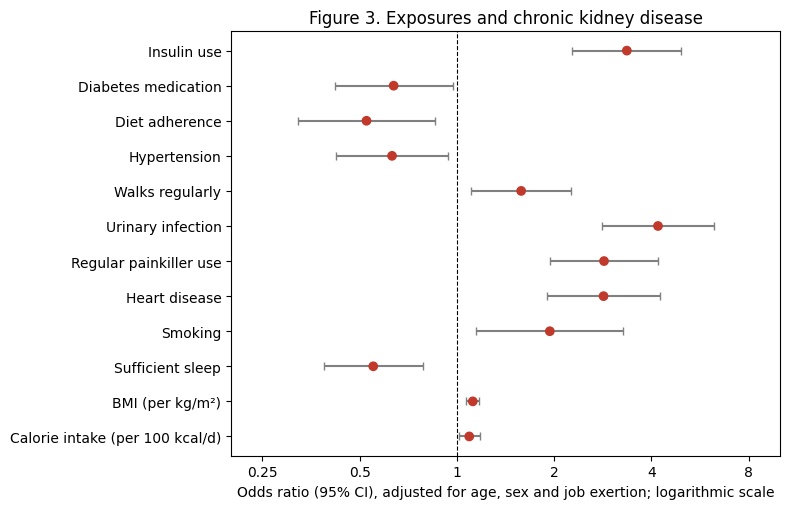

In [11]:
# Forest plot: minimally adjusted ORs
fig, ax = plt.subplots(figsize=(8, 5.2))
res = [(LABELS[v],) + or_ci(clogit(M, list(dict.fromkeys(MIN_ADJ+[v]))), v)[:3] for v in EXPOSURES]
res = pd.DataFrame(res, columns=['lab','or','lo','hi']).iloc[::-1]
sig = (res.lo > 1) | (res.hi < 1)
ax.errorbar(res['or'], range(len(res)), xerr=[res['or']-res.lo, res.hi-res['or']], fmt='none', ecolor='grey', capsize=3)
ax.scatter(res['or'], range(len(res)), c=np.where(sig, '#c0392b', '#34495e'), zorder=3)
ax.axvline(1, ls='--', c='k', lw=0.8); ax.set_xscale('log')
from matplotlib.ticker import FixedLocator, NullLocator
TICKS = [0.25, 0.5, 1, 2, 4, 8]
ax.xaxis.set_major_locator(FixedLocator(TICKS)); ax.xaxis.set_minor_locator(NullLocator())
ax.set_xticklabels([f'{t:g}' for t in TICKS]); ax.set_xlim(0.2, 10)
ax.set_yticks(range(len(res))); ax.set_yticklabels(res.lab)
ax.set_xlabel('Odds ratio (95% CI), adjusted for age, sex and job exertion; logarithmic scale')
ax.set_title('Figure 3. Exposures and chronic kidney disease')
plt.tight_layout()
for ext in ['png', 'pdf']: plt.savefig(f'Figure3_forest.{ext}', dpi=300)
plt.show()

## 6. Sensitivity analyses

In [12]:
# 6a. Exposure lag, number of controls and additional adjustment
# Reported for both the minimally adjusted (primary) and fully adjusted models.
EXTRA = ['water','zarda','urin','fam']
SENS_EXP = EXPOSURES + ['wt_sd']
def sens_column(X, extra=()):
    extra = list(extra); out_min, out_full = {}, {}
    Xw = X.dropna(subset=['wt_sd'])
    f_full = clogit(X, FULL + extra)
    for v in SENS_EXP:
        base = Xw if v == 'wt_sd' else X
        out_min[LABELS[v]] = fmt(or_ci(clogit(base, list(dict.fromkeys(MIN_ADJ + extra + [v]))), v))
        out_full[LABELS[v]] = fmt(or_ci(clogit(Xw, FULL + extra + ['wt_sd']) if v == 'wt_sd' else f_full, v))
    return out_min, out_full

specs = {'Primary (lag 1, m=4)': (dict(lag=1, m=4), ()), 'Lag 3 years': (dict(lag=3, m=4), ()),
         'Lag 1, m=2': (dict(lag=1, m=2), ()), 'Lag 1, m=8': (dict(lag=1, m=8), ()),
         '+ water, zarda, urination, family history': (dict(lag=1, m=4), EXTRA)}
sens_min, sens_full = {}, {}
for name, (kw, extra) in specs.items():
    X = build_sets(**kw); a, b = sens_column(X, extra)
    key = f"{name} [{X.set.nunique()} sets]"; sens_min[key] = a; sens_full[key] = b
table_sens_min = pd.DataFrame(sens_min); table_sens_full = pd.DataFrame(sens_full)
print("Minimally adjusted (primary) models"); display(table_sens_min)
print("Fully adjusted models"); display(table_sens_full)

Minimally adjusted (primary) models


,"Primary (lag 1, m=4) [181 sets]",Lag 3 years [162 sets],"Lag 1, m=2 [181 sets]","Lag 1, m=8 [181 sets]","+ water, zarda, urination, family history [181 sets]"
Insulin use,3.36 (2.27–4.95),2.99 (2.00–4.46),3.69 (2.33–5.85),3.21 (2.21–4.66),3.04 (2.03–4.55)
Diabetes medication,0.64 (0.42–0.97),0.55 (0.35–0.86),0.76 (0.48–1.22),0.77 (0.52–1.15),0.79 (0.51–1.22)
Diet adherence,0.52 (0.32–0.86),0.42 (0.25–0.70),0.52 (0.31–0.89),0.50 (0.32–0.79),0.68 (0.40–1.15)
Hypertension,0.63 (0.42–0.94),0.48 (0.31–0.74),0.67 (0.43–1.05),0.71 (0.49–1.03),0.62 (0.42–0.93)
Walks regularly,1.58 (1.11–2.26),1.43 (0.98–2.09),1.49 (1.00–2.22),1.69 (1.21–2.37),1.89 (1.29–2.75)
Urinary infection,4.19 (2.80–6.27),3.63 (2.38–5.54),3.32 (2.10–5.25),3.42 (2.37–4.93),3.31 (2.16–5.08)
Regular painkiller use,2.85 (1.95–4.18),2.67 (1.82–3.92),2.81 (1.86–4.24),2.85 (2.01–4.04),2.38 (1.59–3.56)
Heart disease,2.84 (1.91–4.24),2.23 (1.48–3.36),1.78 (1.19–2.66),2.22 (1.57–3.12),2.52 (1.65–3.84)
Smoking,1.94 (1.15–3.28),1.67 (0.94–2.95),1.57 (0.85–2.90),2.27 (1.37–3.76),2.10 (1.20–3.64)
Sufficient sleep,0.55 (0.39–0.78),0.66 (0.46–0.96),0.65 (0.45–0.95),0.62 (0.45–0.86),0.60 (0.42–0.86)


Fully adjusted models


,"Primary (lag 1, m=4) [181 sets]",Lag 3 years [162 sets],"Lag 1, m=2 [181 sets]","Lag 1, m=8 [181 sets]","+ water, zarda, urination, family history [181 sets]"
Insulin use,2.48 (1.53–4.00),3.21 (1.99–5.17),3.95 (2.23–6.98),3.14 (2.03–4.87),2.41 (1.47–3.96)
Diabetes medication,1.52 (0.88–2.63),1.22 (0.70–2.14),1.63 (0.87–3.05),1.57 (0.97–2.53),1.61 (0.92–2.80)
Diet adherence,0.43 (0.23–0.81),0.55 (0.29–1.05),0.49 (0.24–1.02),0.51 (0.30–0.86),0.45 (0.24–0.85)
Hypertension,0.36 (0.22–0.58),0.35 (0.22–0.58),0.52 (0.30–0.89),0.40 (0.26–0.61),0.33 (0.20–0.54)
Walks regularly,2.33 (1.48–3.67),1.83 (1.18–2.84),2.30 (1.37–3.86),2.22 (1.52–3.24),2.69 (1.67–4.35)
Urinary infection,2.90 (1.76–4.76),2.18 (1.31–3.64),2.18 (1.22–3.91),2.16 (1.41–3.32),2.35 (1.39–3.98)
Regular painkiller use,2.93 (1.80–4.78),2.18 (1.37–3.47),2.86 (1.69–4.83),2.64 (1.72–4.06),2.69 (1.63–4.42)
Heart disease,2.11 (1.27–3.51),1.71 (1.03–2.84),1.00 (0.59–1.68),1.75 (1.15–2.67),2.07 (1.23–3.49)
Smoking,1.65 (0.89–3.08),1.30 (0.68–2.49),1.27 (0.61–2.65),1.83 (1.03–3.24),1.84 (0.98–3.48)
Sufficient sleep,0.45 (0.28–0.70),0.66 (0.42–1.03),0.59 (0.37–0.95),0.66 (0.45–0.97),0.44 (0.28–0.71)


In [13]:
# 6b. Resampling of controls: repeat matched sampling with 200 different seeds
N_RESAMPLE = 200
draws_min, draws_full = [], []
for s in range(N_RESAMPLE):
    X = build_sets(seed=1000 + s); Xw = X.dropna(subset=['wt_sd'])
    f = clogit(X, FULL); r_full = np.exp(f.params[EXPOSURES]).to_dict()
    r_full['wt_sd'] = np.exp(clogit(Xw, FULL + ['wt_sd']).params['wt_sd'])
    r_min = {v: np.exp(clogit(Xw if v == 'wt_sd' else X, list(dict.fromkeys(MIN_ADJ + [v]))).params[v]) for v in SENS_EXP}
    draws_min.append(r_min); draws_full.append(r_full)
def summ(dr):
    dr = pd.DataFrame(dr)
    t = pd.DataFrame({'Median OR': dr.median(), '2.5th pct': dr.quantile(.025), '97.5th pct': dr.quantile(.975)}).round(2)
    t.index = [LABELS[v] for v in t.index]; return t
resample_min = summ(draws_min); resample_full = summ(draws_full)
print(f"{N_RESAMPLE} resamples — minimally adjusted (primary)"); display(resample_min)
print("Fully adjusted"); display(resample_full)

200 resamples — minimally adjusted (primary)


,Median OR,2.5th pct,97.5th pct
Insulin use,3.16,2.70,3.76
Diabetes medication,0.73,0.60,0.87
Diet adherence,0.53,0.43,0.65
Hypertension,0.61,0.54,0.72
Walks regularly,1.55,1.36,1.81
Urinary infection,3.46,2.88,4.25
Regular painkiller use,2.61,2.17,3.06
Heart disease,2.18,1.83,2.64
Smoking,1.99,1.61,2.49
Sufficient sleep,0.65,0.55,0.73


Fully adjusted


,Median OR,2.5th pct,97.5th pct
Insulin use,2.89,2.34,3.51
Diabetes medication,1.34,1.04,1.71
Diet adherence,0.58,0.42,0.79
Hypertension,0.42,0.34,0.52
Walks regularly,2.07,1.64,2.58
Urinary infection,2.29,1.76,3.06
Regular painkiller use,2.27,1.85,2.89
Heart disease,1.59,1.17,1.93
Smoking,1.66,1.16,2.48
Sufficient sleep,0.63,0.52,0.81


In [14]:
# 6c. E-values. Under risk-set sampling the OR estimates the rate ratio, so no rare-outcome conversion is needed.
def evalue(rr):
    rr = 1/rr if rr < 1 else rr
    return rr + np.sqrt(rr*(rr-1))
def ev_row(t):
    o, lo, hi = t[:3]
    lim = lo if o > 1 else hi
    e_ci = 1.0 if (lo <= 1 <= hi) else evalue(lim)
    return fmt((o, lo, hi)), round(evalue(o), 2), round(e_ci, 2)
full_fit = clogit(M, FULL); MW = M.dropna(subset=['wt_sd']); rows = []
for v in SENS_EXP:
    base = MW if v == 'wt_sd' else M
    tmin = or_ci(clogit(base, list(dict.fromkeys(MIN_ADJ + [v]))), v)
    tfull = or_ci(clogit(MW, FULL + ['wt_sd']), v) if v == 'wt_sd' else or_ci(full_fit, v)
    rows.append([LABELS[v], *ev_row(tmin), *ev_row(tfull)])
evalue_tab = pd.DataFrame(rows, columns=['Exposure','Min-adjusted OR','E-value (point)','E-value (CI limit)',
                                         'Fully adjusted OR','E-value full (point)','E-value full (CI limit)'])
evalue_tab

,Exposure,Min-adjusted OR,E-value (point),E-value (CI limit),Fully adjusted OR,E-value full (point),E-value full (CI limit)
0,Insulin use,3.36 (2.27–4.95),6.17,3.98,2.48 (1.53–4.00),4.39,2.44
1,Diabetes medication,0.64 (0.42–0.97),2.52,1.21,1.52 (0.88–2.63),2.41,1.00
2,Diet adherence,0.52 (0.32–0.86),3.22,1.61,0.43 (0.23–0.81),4.07,1.78
3,Hypertension,0.63 (0.42–0.94),2.55,1.34,0.36 (0.22–0.58),5.05,2.86
4,Walks regularly,1.58 (1.11–2.26),2.54,1.45,2.33 (1.48–3.67),4.10,2.33
5,Urinary infection,4.19 (2.80–6.27),7.85,5.05,2.90 (1.76–4.76),5.24,2.92
6,Regular painkiller use,2.85 (1.95–4.18),5.15,3.30,2.93 (1.80–4.78),5.32,3.00
7,Heart disease,2.84 (1.91–4.24),5.13,3.22,2.11 (1.27–3.51),3.65,1.86
8,Smoking,1.94 (1.15–3.28),3.29,1.56,1.65 (0.89–3.08),2.69,1.00
9,Sufficient sleep,0.55 (0.39–0.78),3.03,1.87,0.45 (0.28–0.70),3.92,2.21


## 7. Walking and hypertension: unexpected associations
Both run opposite to established evidence. The checks below show what the data can support:
* **Crude vs adjusted, and which covariates move the estimate** (negative confounding)
* **Walking:** a static variable reported at interview (after diagnosis for cases), so reverse causation is the likely explanation
* **Hypertension:** checks of how well the variable is recorded, compared with the external benchmark of 67.2% prevalence in type 2 diabetes in BADAS hospitals (Alsaadon et al., *BMC Public Health* 2022)
* **Quantitative bias analysis:** how much misclassification would explain each association

In [15]:
# 7a. One-covariate-at-a-time: which covariates move the crude OR?
rows = []
for v in ['walk','htn']:
    base = or_ci(clogit(M, [v]), v)[0]
    for c in [x for x in FULL if x not in (v,)]:
        rows.append([LABELS[v], LABELS.get(c, c), round(base, 2), round(or_ci(clogit(M, [v, c]), v)[0], 2)])
shift = pd.DataFrame(rows, columns=['Exposure','Added covariate','Crude OR','OR with covariate'])
shift['Change'] = (shift['OR with covariate'] - shift['Crude OR']).round(2)
shift_top = (shift.sort_values(['Exposure','Change'], key=lambda s: s.abs() if s.name=='Change' else s, ascending=[True, False])
             .groupby('Exposure').head(5))
shift_top

,Exposure,Added covariate,Crude OR,OR with covariate,Change
19,Hypertension,BMI (per kg/m²),0.63,0.51,-0.12
29,Hypertension,Sufficient sleep,0.63,0.54,-0.09
26,Hypertension,Regular painkiller use,0.63,0.57,-0.06
25,Hypertension,Urinary infection,0.63,0.58,-0.05
27,Hypertension,Heart disease,0.63,0.59,-0.04
4,Walks regularly,BMI (per kg/m²),1.66,1.86,0.20
8,Walks regularly,Diet adherence,1.66,1.84,0.18
14,Walks regularly,Sufficient sleep,1.66,1.83,0.17
10,Walks regularly,Urinary infection,1.66,1.79,0.13
6,Walks regularly,Insulin use,1.66,1.56,-0.10


In [16]:
# 7b. Correlations of walking and hypertension with other covariates (matched data)
corr_tab = (M[FULL].corr()[['walk','htn']].drop(['walk','htn']).round(2)
            .rename(columns={'walk':'r with walking','htn':'r with hypertension'}))
corr_tab

,r with walking,r with hypertension
age,-0.03,0.06
male,0.02,-0.11
job_int,0.11,-0.00
job_heavy,0.08,-0.07
bmi,-0.11,0.19
cal,0.13,0.03
ins,0.06,-0.02
med,-0.03,0.01
diet,0.16,-0.01
uti,-0.04,0.01


In [17]:
# 7c. Hypertension: is the variable well recorded?
Pv = pd.DataFrame({'case': g.ckd.max(), 'htn_ever': g.htn.max(), 'switches': g.htn.apply(lambda s: (s.diff().abs()==1).sum()),
                   'hd': g.hd.max(), 'age_end': g.age.last(), 'dur_end': g.dy.max(), 'male': g.male.first(),
                   'bmi': g.bmi.first()})
print(f"Ever hypertension: {Pv.htn_ever.mean()*100:.1f}% overall (benchmark in BADAS hospitals: 67.2%)")
print(f"   controls {Pv.loc[Pv.case==0,'htn_ever'].mean()*100:.1f}% | cases {Pv.loc[Pv.case==1,'htn_ever'].mean()*100:.1f}%")
print(f"   diabetes >=15 y: {Pv.loc[Pv.dur_end>=15,'htn_ever'].mean()*100:.1f}% (benchmark >=11 y: 73.4%) | age >=60: {Pv.loc[Pv.age_end>=60,'htn_ever'].mean()*100:.1f}%")
df['age_band'] = pd.cut(df.age, [0,40,50,60,70,120]); df['bmi_band'] = pd.cut(df.bmi, [0,23,25,27.5,60])
print("\nPatient-year prevalence by age band:\n", df.groupby('age_band', observed=True).htn.mean().round(2).to_string())
print("\nPatient-year prevalence by BMI band:\n", df.groupby('bmi_band', observed=True).htn.mean().round(2).to_string())
for c in [0, 1]:
    d = Pv[Pv.case == c]; f = sm.Logit(d.hd, sm.add_constant(d[['htn_ever','age_end','male']])).fit(disp=0)
    print(f"Heart disease ~ hypertension, {'cases' if c else 'controls'}: OR {fmt((np.exp(f.params['htn_ever']),)+tuple(np.exp(f.conf_int().loc['htn_ever'])))}")
print(f"\nPatients who ever change hypertension status: {(Pv.switches>0).sum()} of {Pv.htn_ever.sum()} ever-hypertensive; >2 changes: {(Pv.switches>2).sum()}")

# Collect the checks for Supplementary Table S8
htn_checks = [['Recorded in any year, all patients (%)', round(Pv.htn_ever.mean()*100, 1), '67.2'],
              ['Recorded in any year, patients with CKD (%)', round(Pv.loc[Pv.case==1,'htn_ever'].mean()*100, 1), ''],
              ['Recorded in any year, patients without CKD (%)', round(Pv.loc[Pv.case==0,'htn_ever'].mean()*100, 1), ''],
              ['Recorded in any year, diabetes duration >=15 y (%)', round(Pv.loc[Pv.dur_end>=15,'htn_ever'].mean()*100, 1), '73.4 (>=11 y)'],
              ['Recorded in any year, age >=60 y (%)', round(Pv.loc[Pv.age_end>=60,'htn_ever'].mean()*100, 1), '']]
htn_checks += [[f'Patient-year prevalence, age {b} (%)', round(v*100), ''] for b, v in df.groupby('age_band', observed=True).htn.mean().items()]
htn_checks += [[f'Patient-year prevalence, BMI {b} (%)', round(v*100), ''] for b, v in df.groupby('bmi_band', observed=True).htn.mean().items()]
for c in [0, 1]:
    d = Pv[Pv.case == c]; f = sm.Logit(d.hd, sm.add_constant(d[['htn_ever','age_end','male']])).fit(disp=0)
    htn_checks.append([f"Heart disease vs hypertension, OR, {'with' if c else 'without'} CKD",
                       fmt((np.exp(f.params['htn_ever']),)+tuple(np.exp(f.conf_int().loc['htn_ever']))), ''])
htn_checks += [['Patients with hypertension recorded in any year, n', int(Pv.htn_ever.sum()), ''],
               ['Changed status at least once, n', int((Pv.switches>0).sum()), ''],
               ['Changed status more than twice, n', int((Pv.switches>2).sum()), '']]

Ever hypertension: 36.2% overall (benchmark in BADAS hospitals: 67.2%)
   controls 40.9% | cases 30.8%
   diabetes >=15 y: 34.4% (benchmark >=11 y: 73.4%) | age >=60: 39.8%

Patient-year prevalence by age band:
 age_band
(0, 40]      0.25
(40, 50]     0.30
(50, 60]     0.30
(60, 70]     0.33
(70, 120]    0.22

Patient-year prevalence by BMI band:
 bmi_band
(0.0, 23.0]     0.25
(23.0, 25.0]    0.26
(25.0, 27.5]    0.30
(27.5, 60.0]    0.40
Heart disease ~ hypertension, controls: OR 1.16 (0.57–2.35)
Heart disease ~ hypertension, cases: OR 1.12 (0.59–2.13)

Patients who ever change hypertension status: 44 of 145 ever-hypertensive; >2 changes: 15


In [18]:
# 7d. Hypertension association restricted to matched sets where no member changes hypertension status in the window
stable_ids = Pv.index[Pv.switches == 0]
Ms = M[M.groupby('set').id.transform(lambda s: s.isin(stable_ids).all())]
print(f"Stable-coding sets: {Ms.set.nunique()}")
print("Hypertension OR, crude:", fmt(or_ci(clogit(Ms, ['htn']), 'htn')),
      "| min-adjusted:", fmt(or_ci(clogit(Ms, MIN_ADJ + ['htn']), 'htn')))
htn_checks += [[f'Stable-coding sets ({Ms.set.nunique()}), OR, crude', fmt(or_ci(clogit(Ms, ['htn']), 'htn')), ''],
               [f'Stable-coding sets ({Ms.set.nunique()}), OR, minimally adjusted', fmt(or_ci(clogit(Ms, MIN_ADJ + ['htn']), 'htn')), '']]
htn_check_tab = pd.DataFrame(htn_checks, columns=['Measure', 'Value', 'External benchmark'])
htn_check_tab

Stable-coding sets: 116
Hypertension OR, crude: 0.48 (0.29–0.80) | min-adjusted: 0.51 (0.31–0.84)


,Measure,Value,External benchmark
0,"Recorded in any year, all patients (%)",36.2,67.2
1,"Recorded in any year, patients with CKD (%)",30.8,
2,"Recorded in any year, patients without CKD (%)",40.9,
3,"Recorded in any year, diabetes duration >=15 y...",34.4,73.4 (>=11 y)
4,"Recorded in any year, age >=60 y (%)",39.8,
5,"Patient-year prevalence, age (0, 40] (%)",25,
6,"Patient-year prevalence, age (40, 50] (%)",30,
7,"Patient-year prevalence, age (50, 60] (%)",30,
8,"Patient-year prevalence, age (60, 70] (%)",33,
9,"Patient-year prevalence, age (70, 120] (%)",22,


In [19]:
# 7e. Quantitative bias analysis (fully adjusted model refitted in each simulation)
N_SIM = 200
rng = np.random.default_rng(SEED)
def summarise_sims(vals):
    vals = np.array(vals); return np.median(vals[:,0]), np.mean(vals[:,1])

# Walking: a share of case walkers began walking only after diagnosis -> reclassify as non-walkers
walk_rows = []
case_walk_idx = M.index[(M.y == 1) & (M.walk >= 0.5)]
for share in [0, .05, .10, .15, .20, .25, .30]:
    sims = []
    for _ in range(N_SIM if share else 1):
        X = M.copy()
        k = int(round(share * len(case_walk_idx)))
        if k: X.loc[rng.choice(case_walk_idx, k, replace=False), 'walk'] = 0.0
        o, lo, hi, p = or_ci(clogit(X, FULL), 'walk'); sims.append((o, lo > 1))
    med, frac = summarise_sims(sims)
    walk_rows.append([f'{int(share*100)}%', round(med, 2), f'{frac*100:.0f}%'])
walk_bias = pd.DataFrame(walk_rows, columns=['Case walkers reclassified','Median OR','% sims with CI > 1'])

# Hypertension: with recording sensitivity Se in cases, add true hypertension to some cases recorded as 0
htn_rows = []
case_pos = M.index[(M.y == 1) & (M.htn > 0)]; case_neg = M.index[(M.y == 1) & (M.htn == 0)]
for se in [1.0, .9, .8, .7, .6, .5, .46]:
    sims = []
    for _ in range(N_SIM if se < 1 else 1):
        X = M.copy()
        k = min(int(round(len(case_pos) * (1/se - 1))), len(case_neg))
        if k: X.loc[rng.choice(case_neg, k, replace=False), 'htn'] = 1.0
        o, lo, hi, p = or_ci(clogit(X, FULL), 'htn'); sims.append((o, hi < 1))
    med, frac = summarise_sims(sims)
    htn_rows.append([f'{se:.2f}', round(med, 2), f'{frac*100:.0f}%'])
htn_bias = pd.DataFrame(htn_rows, columns=['Recording sensitivity in cases','Median OR','% sims with CI < 1'])
display(walk_bias); display(htn_bias)
print("Se = 0.46 corresponds to 30.8% recorded vs ~67% expected prevalence in cases (illustrative assumption).")

,Case walkers reclassified,Median OR,% sims with CI > 1
0,0%,2.33,100%
1,5%,1.92,100%
2,10%,1.56,74%
3,15%,1.33,0%
4,20%,1.13,0%
5,25%,0.95,0%
6,30%,0.82,0%


,Recording sensitivity in cases,Median OR,% sims with CI < 1
0,1.00,0.36,100%
1,0.90,0.45,100%
2,0.80,0.57,100%
3,0.70,0.77,0%
4,0.60,1.08,0%
5,0.50,1.77,0%
6,0.46,2.28,0%


Se = 0.46 corresponds to 30.8% recorded vs ~67% expected prevalence in cases (illustrative assumption).


## 8. Secondary analysis: reverse-time trajectories
Cases are aligned on years before CKD diagnosis (year 0 = *T*). Matched controls get a pseudo-index at the same diabetes duration. A GEE (patients as clusters, exchangeable correlation) models each time-varying variable as `years_before × group + age + sex`.
* **Group term:** a constant difference between cases and controls (level).
* **Interaction term:** whether the curves diverge as diagnosis approaches. Divergence would suggest reverse causation or an early warning sign.

In [20]:
def build_long(m=4, seed=SEED, back=5):
    rng = np.random.default_rng(seed); rows = []
    for s, (cid, c) in enumerate(CASES.iterrows()):
        T = int(c.onset); lo = T - back
        if lo < int(c.start): lo = int(c.start)
        if T - lo < 3: continue
        elig = CONTROLS[(CONTROLS.start <= lo) & (CONTROLS.end >= T)].index.values
        if len(elig) == 0: continue
        for pid, y in [(cid, 1)] + [(k, 0) for k in rng.choice(elig, min(m, len(elig)), replace=False)]:
            d = REC[pid].loc[lo:T].reset_index()
            d['rel'] = d.dy - T; d['group'] = y; d['set'] = s; d['uid'] = f'{s}_{pid}'
            d['abs_dwt'] = d.wt.diff().abs()
            rows.append(d)
    return pd.concat(rows, ignore_index=True)

LONG = build_long()
LONG['age10'] = LONG.age / 10
traj_rows = []
for v, fam in [('ins', sm.families.Binomial()), ('med', sm.families.Binomial()), ('diet', sm.families.Binomial()),
               ('htn', sm.families.Binomial()), ('abs_dwt', sm.families.Gaussian())]:
    d = LONG.dropna(subset=[v])
    f = smf.gee(f'{v} ~ rel * group + age10 + male', groups='id', data=d, family=fam,
                cov_struct=sm.cov_struct.Exchangeable()).fit()
    eff = 'OR' if v != 'abs_dwt' else 'Diff (kg)'
    tr = (lambda x: np.exp(x)) if v != 'abs_dwt' else (lambda x: x)
    ci = f.conf_int()
    traj_rows.append([LABELS.get(v, 'Absolute yearly weight change'), eff,
                      f"{tr(f.params['group']):.2f} ({tr(ci.loc['group',0]):.2f}–{tr(ci.loc['group',1]):.2f})", fmt_p(f.pvalues['group']),
                      f"{tr(f.params['rel:group']):.2f} ({tr(ci.loc['rel:group',0]):.2f}–{tr(ci.loc['rel:group',1]):.2f})", fmt_p(f.pvalues['rel:group'])])
traj_tab = pd.DataFrame(traj_rows, columns=['Variable','Scale','Case vs control (level)','p level','Divergence per year (interaction)','p interaction'])
traj_tab

,Variable,Scale,Case vs control (level),p level,Divergence per year (interaction),p interaction
0,Insulin use,OR,3.01 (1.79–5.06),<0.001,1.00 (0.89–1.11),0.944
1,Diabetes medication,OR,0.99 (0.59–1.67),0.979,1.10 (0.99–1.22),0.082
2,Diet adherence,OR,0.88 (0.57–1.35),0.552,1.07 (1.00–1.15),0.041
3,Hypertension,OR,0.78 (0.50–1.21),0.267,1.08 (1.02–1.13),0.003
4,Absolute yearly weight change,Diff (kg),0.22 (0.07–0.37),0.003,-0.02 (-0.08–0.04),0.476


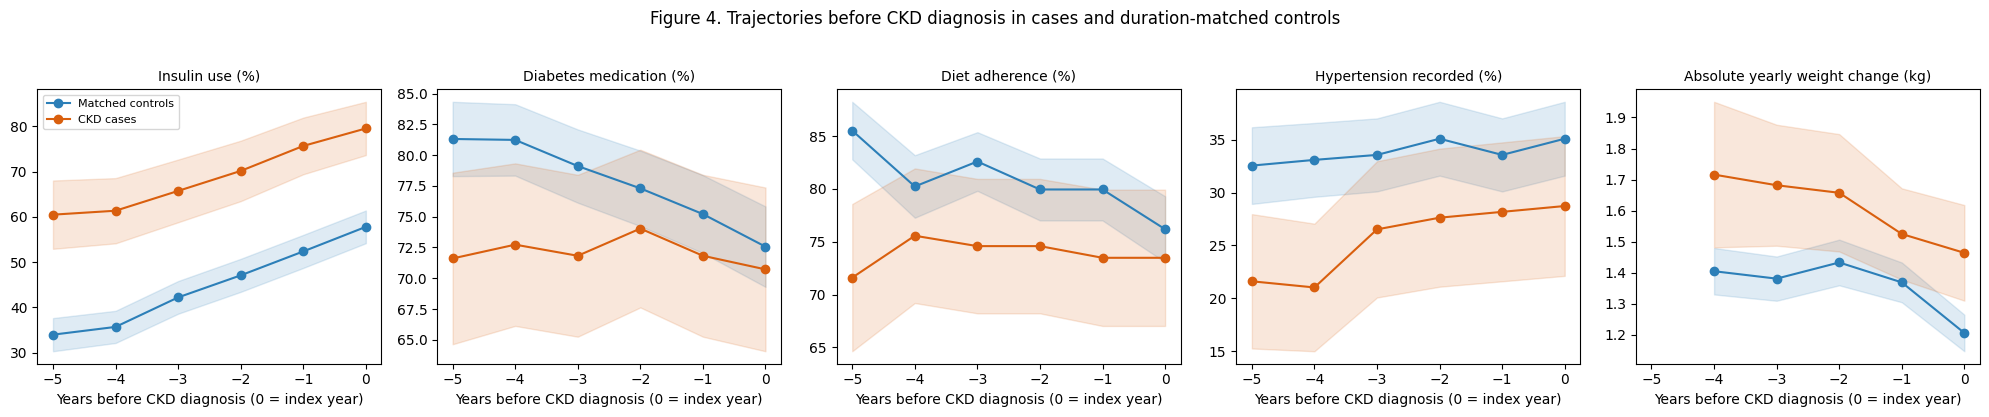

In [21]:
# Figure 4: trajectories before diagnosis (mean ± 95% CI)
panels = [('ins','Insulin use (%)',100), ('med','Diabetes medication (%)',100), ('diet','Diet adherence (%)',100),
          ('htn','Hypertension recorded (%)',100), ('abs_dwt','Absolute yearly weight change (kg)',1)]
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True)
for ax, (v, lab, k) in zip(axes, panels):
    for grp, col, name in [(0, '#2c7fb8', 'Matched controls'), (1, '#d95f0e', 'CKD cases')]:
        s = LONG[LONG.group == grp].groupby('rel')[v].agg(['mean','std','count']).dropna()
        se = s['std'] / np.sqrt(s['count'])
        ax.plot(s.index, s['mean']*k, marker='o', color=col, label=name)
        ax.fill_between(s.index, (s['mean']-1.96*se)*k, (s['mean']+1.96*se)*k, color=col, alpha=.15)
    ax.set_title(lab, fontsize=10); ax.set_xlabel('Years before CKD diagnosis (0 = index year)')
axes[0].legend(fontsize=8)
plt.suptitle('Figure 4. Trajectories before CKD diagnosis in cases and duration-matched controls', y=1.03)
plt.tight_layout()
for ext in ['png', 'pdf']: plt.savefig(f'Figure4_trajectories.{ext}', dpi=300, bbox_inches='tight')
plt.show()

## 9. Weight variability (within the exposure window)

In [22]:
WS = M.dropna(subset=['wt_sd']).copy()
sd_unit = 1.0  # per 1 kg SD of annual weights
for name, cols in [('Crude', ['wt_sd']), ('Min-adjusted', MIN_ADJ + ['wt_sd']), ('Fully adjusted', FULL + ['wt_sd'])]:
    print(f"{name:15s} OR per 1 kg SD: {fmt(or_ci(clogit(WS, cols), 'wt_sd'))}")
for lag in [3]:
    X = build_sets(lag=lag).dropna(subset=['wt_sd'])
    print(f"Lag {lag} years, fully adjusted: {fmt(or_ci(clogit(X, FULL + ['wt_sd']), 'wt_sd'))}")
# Quartiles (cut-points from controls)
cuts = WS.loc[WS.y == 0, 'wt_sd'].quantile([.25, .5, .75]).values
WS['q'] = np.digitize(WS.wt_sd, cuts)
for k in [1, 2, 3]: WS[f'q{k+1}'] = (WS.q == k).astype(int)
f = clogit(WS, MIN_ADJ + ['q2','q3','q4'])
print(f"\nQuartile cut-points (controls): {np.round(cuts, 2)}")
for k in ['q2','q3','q4']: print(f"  {k.upper()} vs Q1: {fmt(or_ci(f, k))}")
f_tr = clogit(WS.assign(qn=WS.q), MIN_ADJ + ['qn']); print(f"  Trend per quartile: p = {fmt_p(f_tr.pvalues['qn'])}")
c = np.round(cuts, 2)
quart_tab = pd.DataFrame([[f'Q1 (<{c[0]})', '1 (reference)'], [f'Q2 ({c[0]} to <{c[1]})', fmt(or_ci(f, 'q2'))],
                          [f'Q3 ({c[1]} to <{c[2]})', fmt(or_ci(f, 'q3'))], [f'Q4 (>={c[2]})', fmt(or_ci(f, 'q4'))],
                          ['P for trend', fmt_p(f_tr.pvalues['qn'])]], columns=['Weight variability quartile (kg)', 'Min-adjusted OR (95% CI)'])
quart_tab

Crude           OR per 1 kg SD: 1.89 (1.49–2.40)
Min-adjusted    OR per 1 kg SD: 1.95 (1.52–2.50)
Fully adjusted  OR per 1 kg SD: 1.88 (1.40–2.53)
Lag 3 years, fully adjusted: 1.54 (1.21–1.96)

Quartile cut-points (controls): [0.96 1.14 1.58]
  Q2 vs Q1: 2.11 (1.05–4.23)
  Q3 vs Q1: 1.55 (0.90–2.66)
  Q4 vs Q1: 3.70 (2.20–6.24)
  Trend per quartile: p = <0.001


,Weight variability quartile (kg),Min-adjusted OR (95% CI)
0,Q1 (<0.96),1 (reference)
1,Q2 (0.96 to <1.14),2.11 (1.05–4.23)
2,Q3 (1.14 to <1.58),1.55 (0.90–2.66)
3,Q4 (>=1.58),3.70 (2.20–6.24)
4,P for trend,<0.001


## 10. Export of all tables
All tables are written to `CKD_results.xlsx` (one sheet per manuscript or supplementary table); Figures 3 and 4 are saved as PNG and PDF. In Colab, download them from the Files panel on the left.

In [ ]:
with pd.ExcelWriter('CKD_results.xlsx') as w:
    table1.to_excel(w, sheet_name='Table1_characteristics', index=False)
    table2.to_excel(w, sheet_name='Table2_primary_clogit', index=False)
    table_sens_min.to_excel(w, sheet_name='Table3_sensitivity_min_adj')
    traj_tab.to_excel(w, sheet_name='Table4_trajectories', index=False)
    const_tab.to_excel(w, sheet_name='S1_within_patient_change', index=False)
    repro_tab.to_excel(w, sheet_name='S2_descriptor_reproduction', index=False)
    pd.concat({'Minimally adjusted': resample_min, 'Fully adjusted': resample_full}, axis=1).to_excel(w, sheet_name='S3_resampling')
    table_sens_full.to_excel(w, sheet_name='S4_sensitivity_full_adj')
    evalue_tab.to_excel(w, sheet_name='S5_evalues', index=False)
    shift_top.to_excel(w, sheet_name='S6_walk_htn_covariates', index=False)
    corr_tab.to_excel(w, sheet_name='S6_walk_htn_correlations')
    walk_bias.to_excel(w, sheet_name='S7_bias_walking', index=False)
    htn_bias.to_excel(w, sheet_name='S7_bias_hypertension', index=False)
    htn_check_tab.to_excel(w, sheet_name='S8_hypertension_checks', index=False)
    quart_tab.to_excel(w, sheet_name='S9_weight_quartiles', index=False)
print("Saved CKD_results.xlsx")

Saved CKD_results.xlsx
